## Lab 08: Communicating Uncertainty

Your name(s): ___________________________

**The Scenario:** 
Rumors are circulating that a local bar called *The Swamp* is shortchanging students on "Large" orders of french fries. Over the course of the semester, you and a few friends smuggled a digital scale and a notebook into the bar. You purchased 40 Large orders and carefully counted the exact number of individual fries in each order.

Your 40 counts are in. Now, you need to analyze the data, quantify your uncertainty, and defend your statistical claims against heavy skepticism.

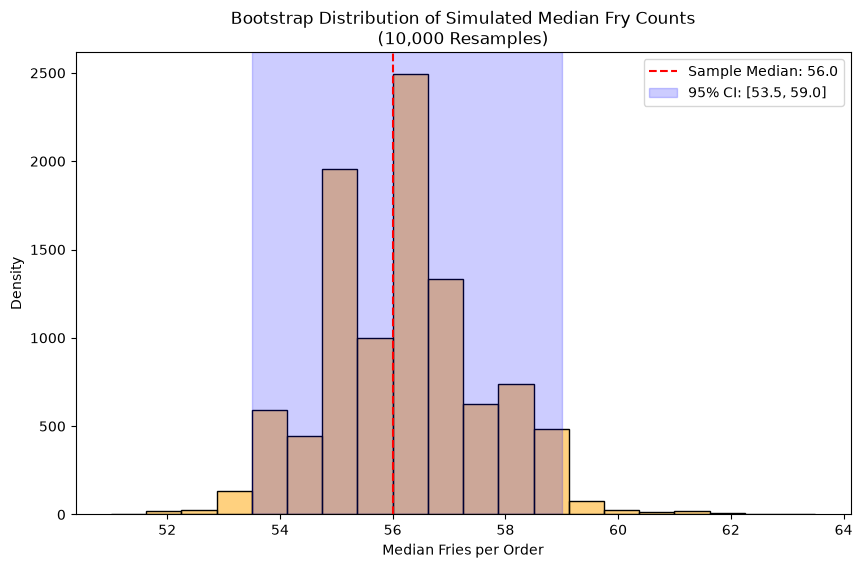

Original Sample Median: 56.0
95% Confidence Interval for the Median: [53.5, 59.0]


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set seed so the whole class gets the same baseline simulation
np.random.seed(42)

# Our Original Sample (Nature's Loop)
# 40 physical orders of fries, counted manually. Notice a few massive outliers.
fry_counts = np.array([
    42, 45, 48, 48, 49, 50, 51, 51, 52, 52, 53, 53, 54, 54, 55, 
    55, 55, 56, 56, 57, 57, 58, 58, 59, 59, 60, 61, 62, 63, 64, 
    65, 68, 71, 72, 75, 82, 88, 41, 39, 95
])

def generate_bootstrap_ci(data, num_bootstraps=10000, confidence_level=95):
    """
    Generates a bootstrap confidence interval for the median using vectorized NumPy operations.
    """
    n = len(data)
    
    # Level 2: Our Loop (Computational) 
    # Draw with replacement to simulate 10,000 new API pulls from our sample
    bootstrap_samples = np.random.choice(data, size=(num_bootstraps, n), replace=True)
    
    # Calculate the median for all 10,000 simulated samples simultaneously
    bootstrap_medians = np.median(bootstrap_samples, axis=1)
    
    # Chop the tails to find the interval bounds (e.g., 2.5th and 97.5th percentiles)
    tail_percent = (100 - confidence_level) / 2
    lower_bound = np.percentile(bootstrap_medians, tail_percent)
    upper_bound = np.percentile(bootstrap_medians, 100 - tail_percent)
    
    # Plotting the distribution
    plt.figure(figsize=(10, 6))
    sns.histplot(bootstrap_medians, fill=True, color="orange", alpha=0.5, bins = 20)
    
    # Add visual markers
    plt.axvline(np.median(data), color='red', linestyle='--', 
                label=f'Sample Median: {np.median(data):.1f}')
    plt.axvspan(lower_bound, upper_bound, color='blue', alpha=0.2, 
                label=f'{confidence_level}% CI: [{lower_bound:.1f}, {upper_bound:.1f}]')
    
    plt.title("Bootstrap Distribution of Simulated Median Fry Counts\n(10,000 Resamples)")
    plt.xlabel("Median Fries per Order")
    plt.ylabel("Density")
    plt.legend()
    plt.show()
    
    return lower_bound, upper_bound

# Run the simulation
lower, upper = generate_bootstrap_ci(fry_counts)
print(f"Original Sample Median: {np.median(fry_counts)}")
print(f"95% Confidence Interval for the Median: [{lower:.1f}, {upper:.1f}]")

### Exercise 1: The Student Newspaper Headline

You ran the bootstrap simulation. The editor of the student newspaper wants to publish your findings with the following headline: 

> *"Math Proves Serving Size of Fries at Local Bar is 55.5, Plus or Minus 3.5!"*

**Your Task:** 
Explain to the editor why this headline is misleading. Rewrite the headline and write a two-sentence caption for the general student body that accurately describes what your interval actually guarantees. **Do not use the words "Bootstrap," "Sampling Distribution," or "Population."**

### Deliverable 2: The Dining Hall Director's Rebuttal

The paper publishes your findings. The next morning, the Director of Dining Services furiously emails you: 

> *"Your algorithm is broken. I personally went down to the kitchen yesterday, counted 40 large orders, and the median was 64 fries. The true median isn't in your interval at all!"*

**Your Task:** 
Write an email back to the Director defending your interval. How do you explain the validity of your 95% confidence procedure when the Director possesses a sample that falls completely outside of your bounds?

### Deliverable 3: The Plot Thickens

A whistleblower in the kitchen reveals a terrifying fact about your data: The 40 orders you analyzed were all purchased between 9:45 PM and 10:00 PM, right before the grill closes. The workers usually just dump whatever fries are left in the basket into the final few boxes so they can clean the fryers faster. 

**Your Task:** 
Does this new information change the width of the confidence interval you calculated earlier? Does it change your confidence in the overall procedure? 

### Deliverable 4: Skill Check

What is the difference between the *variance of our original sample* (how spread out our 40 physical fry counts are) and the *variance of the bootstrap distribution* (how spread out the 10,000 simulated medians are in the orange graph above)?